# Classical ML: dummy, logistic regression, BM25, tree, MLP (notebook 02)

Part A walks through one seed-0 split with the pipeline from the course slides: dummy
baselines, TF-IDF logistic regression with a threshold picked on validation, BM25, a decision
tree and an MLP, then explanations and error reading. Only training and validation rows
are used there. Part B runs the tuned experiment for all five split seeds (finished runs are
reused from `outputs/classical/`, so this is fast unless you delete them), then reads the
saved results: the test split is scored once per (model, seed) inside the run and only read
back afterwards.

Run time: about 5 minutes for part A; part B reads saved files in under a minute, or about
an hour if it has to recompute all 30 runs.

In [1]:
import sys, os; os.chdir(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else None; sys.path.insert(0, "."); import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from modules import data_helper as dh
from modules import features as ft
from modules import models as md
from modules import eval_helper as ev
from modules import explain_helper as eh
from modules import results_helper as rh
from modules import classical_runs as cr
from sklearn.metrics import confusion_matrix, precision_recall_curve

DATA = "../data/fake_job_postings.csv"

In [2]:
SEED = 0
SEEDS = [0, 1, 2, 3, 4]
SPLIT_PATH = "splits/seed0.npz"
OUT_CLASSICAL = "outputs/classical"
GROUPS = ["classical"]  # notebook 03 adds the deep models to the same comparison

dh.seed_everything(SEED)
sns.set_theme(style="whitegrid")

# Part A: one split, validation only

## Setup: the seed-0 split

Load, clean, add features, and reuse the saved seed-0 split (Session 5: split
first, then fit on the training rows only).

In [3]:
df = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))
if os.path.exists(SPLIT_PATH):
    splits = dh.load_splits(SPLIT_PATH, df)
else:
    splits = dh.make_splits(df, seed=SEED)
    dh.save_splits(SPLIT_PATH, splits, df)
assert not set(splits["train"]) & set(splits["val"]), "train/val row overlap"
train = df.iloc[splits["train"]]
val = df.iloc[splits["val"]]
y_train = train["fraudulent"].to_numpy()
y_val = val["fraudulent"].to_numpy()

In [4]:
y_all = df["fraudulent"].to_numpy()
for name in ("train", "val", "test"):
    idx = splits[name]
    print(f"{name:5s}: {len(idx):6d} rows, {int(y_all[idx].sum()):4d} fraud ({y_all[idx].mean():.1%})")
print("test rows are listed for completeness; this notebook never scores them")

train:  10559 rows,  514 fraud (4.9%)
val  :   3520 rows,  171 fraud (4.9%)
test :   3520 rows,  171 fraud (4.9%)
test rows are listed for completeness; this notebook never scores them


## One helper for every model

The same three steps each time: fit on train, pick the decision threshold on
validation (never on test), then report train and validation side by side so the
generalisation gap is visible (Session 6). `ev.compare_table` names its second split
"test"; we pass validation metrics there and rename the columns below, so the test
rows are never touched.

In [5]:
fitted, thresholds, scores, results = {}, {}, {}, {}

def report(name, model):
    """Score a fitted model; the threshold is picked on validation only."""
    s_val = ev.score_of(model, val)
    thr = ev.pick_threshold(y_val, s_val)
    results[name] = {"train": ev.evaluate(y_train, ev.score_of(model, train), thr),
                     "test": ev.evaluate(y_val, s_val, thr)}
    fitted[name], thresholds[name], scores[name] = model, thr, s_val
    out = pd.DataFrame(results[name]).T.rename(index={"test": "val"})  # "test" slot holds validation
    out = out[["pr_auc", "roc_auc", "f1", "precision", "recall"]]
    out.insert(0, "model", name)
    return out

## The dummy baseline (Sessions 6/7)

Every model has to beat the dumb references first: `dummy_majority` always predicts
the majority class; `dummy_stratified` guesses the class at the training rates.

In [6]:
frames = [report(name, est.fit(train, y_train))
          for name, est in md.get_baselines(SEED).items()]
pd.concat(frames)

,model,pr_auc,roc_auc,f1,precision,recall
train,dummy_majority,0.048679,0.500000,0.092838,0.048679,1.0
val,dummy_majority,0.048580,0.500000,0.092658,0.048580,1.0
train,dummy_stratified,0.048919,0.502372,0.092838,0.048679,1.0
val,dummy_stratified,0.048471,0.498783,0.092658,0.048580,1.0


## Logistic regression on TF-IDF + engineered features

`modules/models.py` builds one Pipeline: TF-IDF over the joined text, one-hot and
ordinal encoded metadata, scaled numeric flags, then a `class_weight="balanced"`
logistic regression.

In [7]:
report("logreg", md.get_models(SEED)["logreg"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,logreg,0.979949,0.999025,0.915323,0.949791,0.883268
val,logreg,0.824794,0.980151,0.773163,0.852113,0.707602


### Confusion matrix on validation

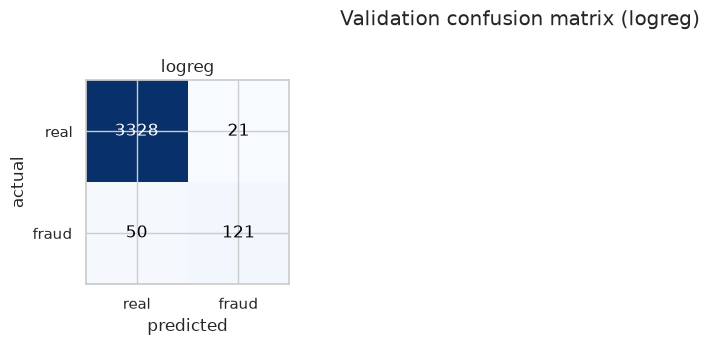

In [8]:
m = results["logreg"]["test"]  # validation metrics (see the helper above)
cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
ev.plot_confusions({"logreg": cm}, ["real", "fraud"],
                   title="Validation confusion matrix (logreg)")
plt.show()

Reading: rows are the actual class, columns the predicted one; the diagonal holds
the correct calls.

### The threshold trade-off

Session 6: with an imbalanced target there is no free lunch between precision and
recall; the threshold is a business decision, and we pick it on validation.

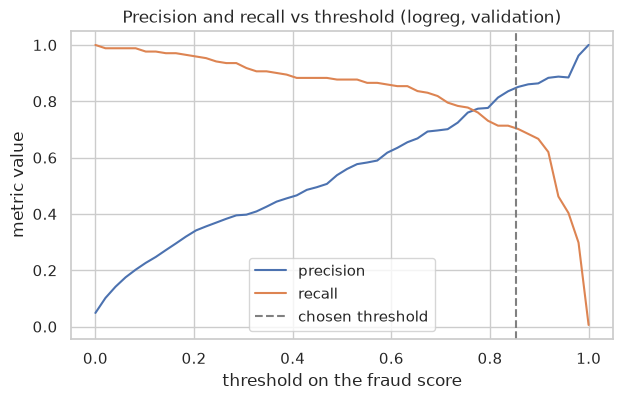

In [9]:
sw = ev.sweep_thresholds(y_val, scores["logreg"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sw["threshold"], sw["precision"], label="precision")
ax.plot(sw["threshold"], sw["recall"], label="recall")
ax.axvline(thresholds["logreg"], color="grey", linestyle="--", label="chosen threshold")
ax.set_xlabel("threshold on the fraud score")
ax.set_ylabel("metric value")
ax.set_title("Precision and recall vs threshold (logreg, validation)")
ax.legend()
plt.show()

Reading: the dashed line is the threshold picked on validation; moving it right can
only shrink the set of flagged ads.

## BM25 instead of TF-IDF

BM25 is the ranking function behind classic search engines. It differs from TF-IDF
in two ways: repeating a word has diminishing returns (saturating term frequency),
and long ads are discounted relative to the average ad length (length normalisation).
The vocabulary and everything else in the pipeline are identical, so any difference
in the numbers comes from the weighting alone.

In [10]:
report("logreg_bm25", md.get_models(SEED)["logreg_bm25"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,logreg_bm25,0.982686,0.999157,0.935211,0.903811,0.968872
val,logreg_bm25,0.827157,0.980638,0.778761,0.785714,0.771930


## Decision tree

Easy to read, prone to overfitting on sparse text. `tree_rules` prints the top
levels of the fitted tree; `top_tree_features` lists the features it leans on.

In [11]:
report("tree", md.get_models(SEED)["tree"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,tree,0.981589,0.999052,0.907084,0.860384,0.959144
val,tree,0.504271,0.886966,0.668394,0.600000,0.754386


In [12]:
print(eh.tree_rules(fitted["tree"], max_depth=3))

|--- binary__missing_company_profile <= 0.50
|   |--- text__encouraged <= 0.04
|   |   |--- text__process provide <= 0.05
|   |   |   |--- text__high school <= 0.05
|   |   |   |   |--- truncated branch of depth 12
|   |   |   |--- text__high school >  0.05
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- text__process provide >  0.05
|   |   |   |--- text__professional <= 0.03
|   |   |   |   |--- class: 0
|   |   |   |--- text__professional >  0.03
|   |   |   |   |--- truncated branch of depth 2
|   |--- text__encouraged >  0.04
|   |   |--- text__growing <= 0.02
|   |   |   |--- text__looking <= 0.04
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- text__looking >  0.04
|   |   |   |   |--- class: 0
|   |   |--- text__growing >  0.02
|   |   |   |--- class: 0
|--- binary__missing_company_profile >  0.50
|   |--- ordinal__required_experience <= 1.62
|   |   |--- binary__has_company_logo <= 0.50
|   |   |   |--- text__web <= 0.05
|   |   |   |   |--- tru

In [13]:
eh.top_tree_features(fitted["tree"], k=10)

,term,importance
0,binary__missing_company_profile,0.293195
1,text__encouraged,0.144615
2,text__process provide,0.058810
3,text__high school,0.045802
4,ordinal__required_experience,0.039196
5,text__income,0.035713
6,text__real estate,0.024856
7,text__calls,0.019856
8,binary__has_company_logo,0.019425
9,text__telecommunication,0.016576


## MLP on the same features

A small sklearn neural network. It has no `class_weight`, so we rely on the ranking
of its scores plus the threshold picked on validation (Session 5).

In [14]:
report("mlp", md.get_models(SEED)["mlp"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,mlp,0.993849,0.998611,0.980431,0.986220,0.974708
val,mlp,0.899189,0.986176,0.856269,0.897436,0.818713


## All models side by side

Train versus validation PR-AUC per model; the gap column is the generalisation gap.
This is validation, not test: part B scores the test split once per (model, seed).

In [15]:
table = ev.compare_table(results).rename(columns=lambda c: c.replace("test_", "val_"))
table.sort_values("val_pr_auc", ascending=False)

,model,train_pr_auc,val_pr_auc,train_f1,val_f1,train_recall,val_recall,train_precision,val_precision,gap
5,mlp,0.993849,0.899189,0.980431,0.856269,0.974708,0.818713,0.986220,0.897436,0.094660
3,logreg_bm25,0.982686,0.827157,0.935211,0.778761,0.968872,0.771930,0.903811,0.785714,0.155528
2,logreg,0.979949,0.824794,0.915323,0.773163,0.883268,0.707602,0.949791,0.852113,0.155154
4,tree,0.981589,0.504271,0.907084,0.668394,0.959144,0.754386,0.860384,0.600000,0.477317
0,dummy_majority,0.048679,0.048580,0.092838,0.092658,1.000000,1.000000,0.048679,0.048580,0.000099
1,dummy_stratified,0.048919,0.048471,0.092838,0.092658,1.000000,1.000000,0.048679,0.048580,0.000448


## Hyper-parameter tuning (switched off)

Part B below runs the full random search over all models and five seeds:
grouped cross-validation on the training rows only, scoring PR-AUC (Session 7). The
flag below runs a tiny live version (`n_iter=3, cv=3`); keep it False during the
demo.

In [16]:
RUN_TUNING = False  # flip to True to run a small random search live (slow)

if RUN_TUNING:
    # Grouped CV on the training rows so duplicate descriptions cannot leak across folds.
    search = md.tune(md.get_models(SEED)["logreg"], md.PARAM_GRIDS["logreg"],
                     train, y_train, train["group"].to_numpy(),
                     n_iter=3, cv=3, seed=SEED)
    print("best params:", search.best_params_)
    print("CV PR-AUC:", round(float(search.best_score_), 3))

## Which words drive the logreg?

Session 6: read the model. `top_linear_terms` maps the coefficients back to feature
names recovered from the fitted ColumnTransformer.

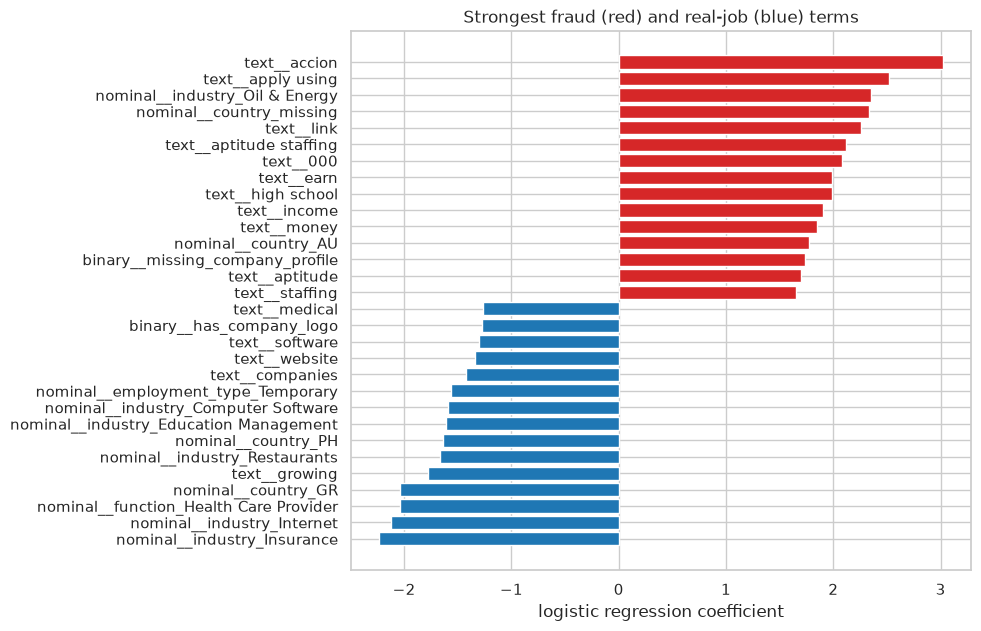

In [17]:
terms = eh.top_linear_terms(fitted["logreg"], k=15).sort_values("coef")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(terms["term"], terms["coef"],
        color=np.where(terms["coef"] > 0, "tab:red", "tab:blue"))
ax.set_xlabel("logistic regression coefficient")
ax.set_title("Strongest fraud (red) and real-job (blue) terms")
plt.show()

Reading: red bars push an ad towards fraud and blue bars towards real; bar length is
the coefficient, not the importance of a whole input column.

## Which columns matter? Permutation importance

Shuffle one raw input column at a time and see how much validation PR-AUC drops
(Session 6). We use a 1000-row validation sample and a single repeat to keep it
quick.

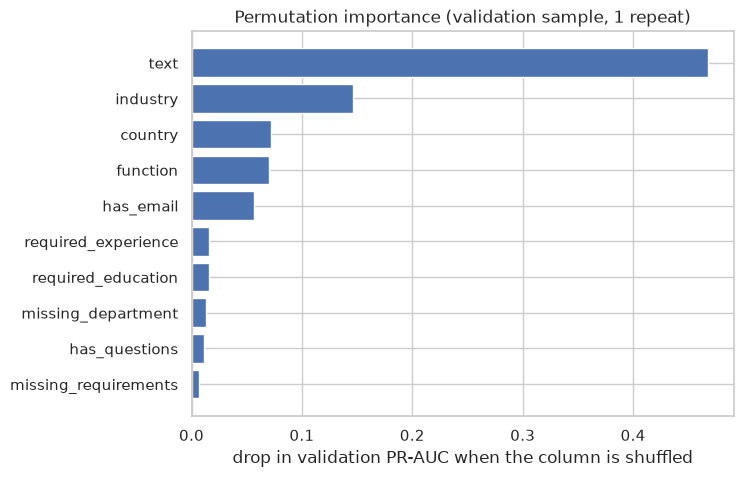

In [18]:
val_sample = val.sample(min(1000, len(val)), random_state=SEED)
perm = eh.permutation_table(fitted["logreg"], val_sample,
                            val_sample["fraudulent"].to_numpy(),
                            n_repeats=1, seed=SEED)
top = perm.head(10).iloc[::-1]  # reversed so the biggest bar lands on top
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top["col"], top["importance_mean"])
ax.set_xlabel("drop in validation PR-AUC when the column is shuffled")
ax.set_title("Permutation importance (validation sample, 1 repeat)")
plt.show()

Reading: the longer the bar, the more the model leaned on that single input column;
near-zero bars mean the column was barely used.

## Read the errors (Session 6)

The five most confident false positives (flagged, but real) and false negatives
(not flagged, but fraud) of the logreg on validation.

In [19]:
errors = eh.show_errors(val, y_val, scores["logreg"], thresholds["logreg"], k=5)
for _, e in errors.iterrows():
    print(f"[{e['error_type']}] score={e['score']:.3f}  title: {e['title']}")
    print(e["description"], "\n")

[false_positive] score=0.990  title: Customer Service 
Our client is seeking an Customer Service with 1 plus years of experience.The ideal candidate must have-1 plus years of experience in the support role-Calendar, scheduling, correspondence, phones-Conf 

[false_positive] score=0.988  title: Human Resources Administrator
JOB DESCRIPTIONThe Human Resources Administrator manages the day-to-day operations of the Human Resource office. The HR Administrator manages the administration of the human resources policies, proced 

[false_positive] score=0.977  title: Entry Level Controller: FT & PT
Are you looking to advance your bookkeeping career with a company that is growing at an exponential rate? Are you a pro with QuickBooks? Are you ready to step up to an Entry Level Controller or a Full 

[false_positive] score=0.977  title: Tankage
A company in oil &amp; gas that has grown into one of Malaysia’s leading integrated specialist technical services providers to the oil, gas and petrochemic

## Per-group check: employment type

Session 6: a model can look fine on average and still fail one group. Recall and
precision by employment type at the logreg's validation threshold.

In [20]:
pred_val = (scores["logreg"] >= thresholds["logreg"]).astype(int)
ev.group_breakdown(y_val, pred_val, val["employment_type"])

,group,count,positives,recall,precision
0,Contract,254,9,0.222222,0.400000
1,Full-time,2274,93,0.752688,0.864198
2,Other,38,0,NaN,0.000000
3,Part-time,151,14,0.785714,0.785714
4,Temporary,65,1,1.000000,1.000000
5,NaN,738,54,0.685185,0.925000


Reading: rows with few ads have noisy recall and precision; the count column says
how much to trust each row.

# Part B: tuned runs over five split seeds

For each seed and model `cr.run_classical` tunes on the training rows (random search, 4
candidates, 3-fold grouped CV, scoring PR-AUC), refits, picks the threshold on validation, and
scores validation and test once. One JSON + NPZ pair per (model, seed) goes to
`outputs/classical/`; pairs that already exist are skipped. Only validation numbers are printed.

In [21]:
RUN_CLASSICAL = True  # False: only read the saved results below
if RUN_CLASSICAL:
    df_all = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))
    cr.run_classical(df_all, SEEDS, out_dir=OUT_CLASSICAL, n_iter=4, cv=3)

seed 0: rows train/val/test = [10559, 3520, 3520], positives = [514, 171, 171]


seed 0 dummy_majority: already done, skipping
seed 0 dummy_stratified: already done, skipping
seed 0 logreg: already done, skipping
seed 0 logreg_bm25: already done, skipping
seed 0 tree: already done, skipping
seed 0 mlp: already done, skipping
seed 1: rows train/val/test = [10559, 3520, 3520], positives = [514, 171, 171]


seed 1 dummy_majority: already done, skipping
seed 1 dummy_stratified: already done, skipping
seed 1 logreg: already done, skipping
seed 1 logreg_bm25: already done, skipping
seed 1 tree: already done, skipping
seed 1 mlp: already done, skipping
seed 2: rows train/val/test = [10559, 3520, 3520], positives = [514, 171, 171]


seed 2 dummy_majority: already done, skipping
seed 2 dummy_stratified: already done, skipping
seed 2 logreg: already done, skipping
seed 2 logreg_bm25: already done, skipping
seed 2 tree: already done, skipping
seed 2 mlp: already done, skipping
seed 3: rows train/val/test = [10559, 3520, 3520], positives = [514, 171, 171]


seed 3 dummy_majority: already done, skipping
seed 3 dummy_stratified: already done, skipping
seed 3 logreg: already done, skipping
seed 3 logreg_bm25: already done, skipping
seed 3 tree: already done, skipping
seed 3 mlp: already done, skipping
seed 4: rows train/val/test = [10559, 3520, 3520], positives = [514, 171, 171]


seed 4 dummy_majority: already done, skipping
seed 4 dummy_stratified: already done, skipping
seed 4 logreg: already done, skipping
seed 4 logreg_bm25: already done, skipping
seed 4 tree: already done, skipping
seed 4 mlp: already done, skipping


# Results of the classical runs

Everything below reads the saved files; nothing is fitted. The same section is repeated in
notebook 03 with the deep models added.

In [22]:
OUT_DEEP = "outputs/deep"
DIRS = {"classical": OUT_CLASSICAL, "deep": OUT_DEEP}


class StopExecution(Exception):
    """Stops the notebook quietly when there is nothing to report."""

    def _render_traceback_(self):
        pass  # IPython hook: an empty traceback, so the notebook just stops

## Load the saved results

`results_helper.load_results` collects one row per (model, seed) from the JSON
files of the groups listed in `GROUPS` (deep results only when `outputs/deep/` is non-empty). If
nothing is found we stop here with a message instead of crashing.

In [23]:
dirs = [d for g, d in DIRS.items() if g in GROUPS and os.path.isdir(d) and os.listdir(d)]
res = rh.load_results(*dirs) if dirs else pd.DataFrame(columns=["group"])
res = res[res["group"].isin(GROUPS)]
if res.empty:
    print("No result files were found. Looked in:", dirs)
    print("Run the experiment cells of this notebook first, then re-run this section.")
    raise StopExecution
print(f"{len(res)} runs found: {res['model'].nunique()} models, "
      f"seeds {sorted(int(x) for x in res['seed'].unique())}")

30 runs found: 6 models, seeds [0, 1, 2, 3, 4]


## Which runs were found

Each cell counts finished runs; a full grid has exactly one run per (model, seed).

In [24]:
res.groupby(["model", "seed"]).size().unstack(fill_value=0)

seed,0,1,2,3,4
model,,,,,
dummy_majority,1,1,1,1,1
dummy_stratified,1,1,1,1,1
logreg,1,1,1,1,1
logreg_bm25,1,1,1,1,1
mlp,1,1,1,1,1
tree,1,1,1,1,1


## Headline test metrics

Mean and standard deviation over seeds, sorted by mean test PR-AUC. The dummy rows
are the floor every real model has to beat. With a single seed there is no standard
deviation and only the mean is shown.

In [25]:
def fmt(col):
    """mean +- std over seeds for one metric; a lone seed has no std."""
    g = res.groupby("model")[col]
    return [f"{m:.3f} +- {s:.3f}" if pd.notna(s) else f"{m:.3f}"
            for m, s in zip(g.mean(), g.std())]

order = res.groupby("model")["test_pr_auc"].mean().sort_values(ascending=False).index
pd.DataFrame({
    "seeds": res.groupby("model").size(),
    "test PR-AUC": fmt("test_pr_auc"),
    "test F1": fmt("test_f1"),
    "test precision": fmt("test_precision"),
    "test recall": fmt("test_recall"),
}).loc[order]

,seeds,test PR-AUC,test F1,test precision,test recall
model,,,,,
logreg_bm25,5,0.847 +- 0.073,0.804 +- 0.055,0.856 +- 0.034,0.760 +- 0.081
mlp,5,0.846 +- 0.077,0.787 +- 0.081,0.863 +- 0.051,0.726 +- 0.106
logreg,5,0.821 +- 0.063,0.772 +- 0.042,0.827 +- 0.052,0.726 +- 0.053
tree,5,0.402 +- 0.066,0.501 +- 0.055,0.434 +- 0.054,0.634 +- 0.165
dummy_stratified,5,0.049 +- 0.001,0.093 +- 0.000,0.049 +- 0.000,1.000 +- 0.000
dummy_majority,5,0.049 +- 0.000,0.093 +- 0.000,0.049 +- 0.000,1.000 +- 0.000


Why the two dummy rows show recall 1.0: a constant score has a single possible threshold,
and picking it by F1 flags every ad as fraud. Their precision therefore equals the
share of fraud in the data, which is the floor every real model has to beat.

## Validation vs test PR-AUC

Validation is what models, hyper-parameters and thresholds were chosen on; test is
the honest number. The difference is the price of that selection.

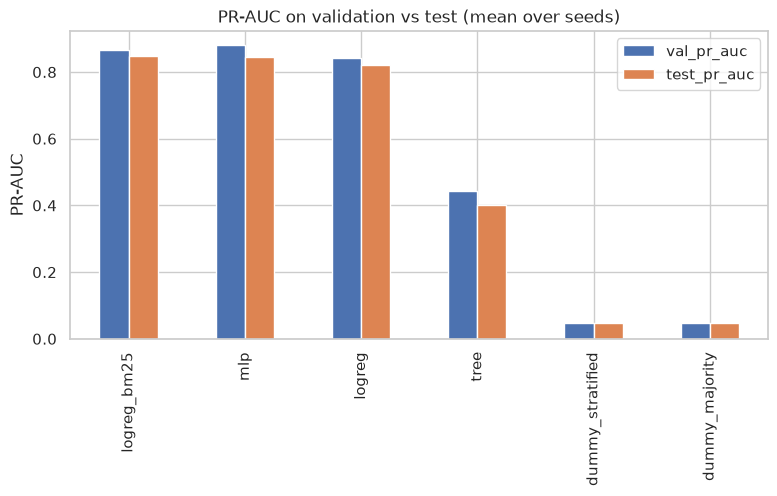

In [26]:
means = res.groupby("model")[["val_pr_auc", "test_pr_auc"]].mean().loc[order]
ax = means.plot(kind="bar", figsize=(9, 4))
ax.set_title("PR-AUC on validation vs test (mean over seeds)")
ax.set_xlabel("")
ax.set_ylabel("PR-AUC")
plt.show()

Reading: each model has two bars, validation and test, on the same 0 to 1 scale;
the validation bar tends to sit at or above the test bar.

## Generalisation gap

Train PR-AUC minus test PR-AUC per model (mean over seeds). A large gap means the
model memorised its training rows.

In [27]:
g = res.groupby("model").agg(train_pr_auc=("train_pr_auc", "mean"),
                             test_pr_auc=("test_pr_auc", "mean"))
g["gap (train - test)"] = g["train_pr_auc"] - g["test_pr_auc"]
g.sort_values("gap (train - test)", ascending=False)

,train_pr_auc,test_pr_auc,gap (train - test)
model,,,
tree,0.638283,0.402411,0.235873
logreg,0.991778,0.820640,0.171139
logreg_bm25,1.000000,0.847136,0.152864
mlp,0.992673,0.846210,0.146463
dummy_majority,0.048679,0.048580,0.000099
dummy_stratified,0.048816,0.048734,0.000082


## Per-seed spread

Session 7 rule of thumb: a model that wins by less than its own standard deviation
has not won. Each point is one split seed.

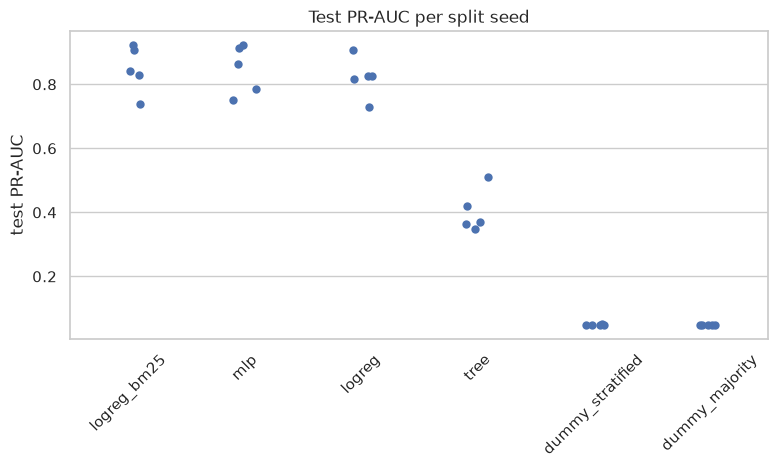

In [28]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.stripplot(data=res, x="model", y="test_pr_auc", order=order, ax=ax, size=6)
ax.set_title("Test PR-AUC per split seed")
ax.set_xlabel("")
ax.set_ylabel("test PR-AUC")
ax.tick_params(axis="x", rotation=45)
plt.show()

Reading: every point is one seed of one model; models whose point clouds overlap
are indistinguishable at this level of noise.

## Seed 0 in detail

The NPZ files hold y and scores for validation and test in the same row order as the
split, so curves and matrices can be rebuilt without refitting anything. If no
seed-0 run exists we stop with a message.

In [29]:
seed0 = res[res["seed"] == 0]
if seed0.empty:
    print("No seed-0 runs found; the remaining sections need seed 0.")
    raise StopExecution
seed_runs = {row["model"]: (rh.load_scores(DIRS[row["group"]], row["model"], 0), row["thr"])
             for _, row in seed0.iterrows()}
y_test = next(iter(seed_runs.values()))[0]["y_test"]
print("seed-0 models:", ", ".join(seed_runs))

seed-0 models: dummy_majority, dummy_stratified, logreg_bm25, logreg, mlp, tree


### Precision-recall curves on the test split (seed 0)

Built from the saved scores with sklearn's `precision_recall_curve`; the dashed line
is the fraud base rate, i.e. what random guessing scores.

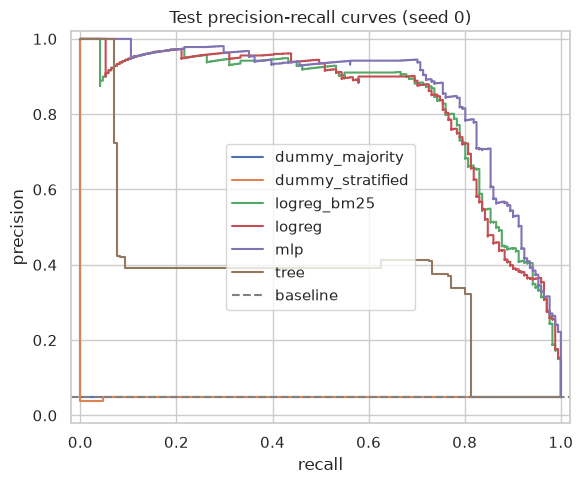

In [30]:
curves = {name: precision_recall_curve(y_test, s["score_test"])[:2]
          for name, (s, thr) in seed_runs.items()}
pos_rate = float(y_test.mean())
ev.plot_pr_curves(curves, pos_rate=pos_rate,
                  title="Test precision-recall curves (seed 0)")
plt.show()

Reading: the x axis is recall, the y axis precision; closer to the top-right corner
is better, and the dashed grey line is the base rate every curve should beat.

### Confusion matrices at the validation-chosen threshold (seed 0)

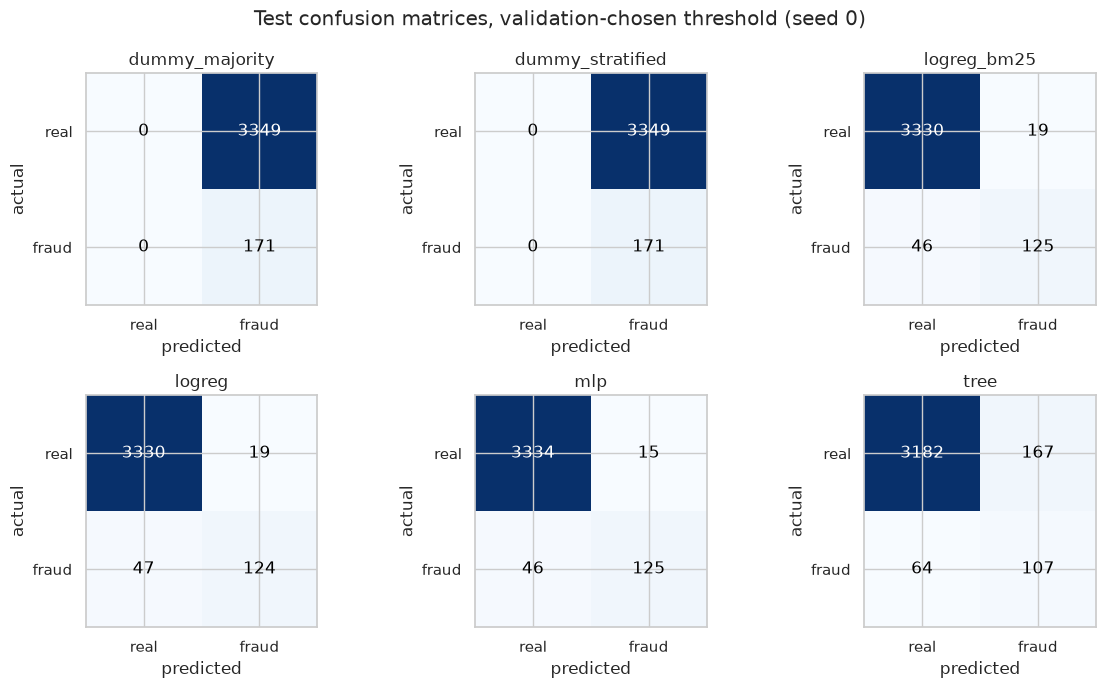

In [31]:
cms = {}
for name, (s, thr) in seed_runs.items():
    pred = (s["score_test"] >= thr).astype(int)
    cms[name] = confusion_matrix(y_test, pred)
ev.plot_confusions(cms, ["real", "fraud"],
                   title="Test confusion matrices, validation-chosen threshold (seed 0)")
plt.show()

Reading: rows are the actual class, columns the predicted class; the diagonal holds
the correct calls.

## Fit time per model

Wall-clock seconds per run (mean over seeds and slowest seed), as recorded by the
runners.

In [32]:
res.groupby("model")["seconds"].agg(["mean", "max"]).sort_values("mean").round(1)

,mean,max
model,,
dummy_majority,0.0,0.0
dummy_stratified,0.0,0.0
logreg,60.8,70.3
logreg_bm25,78.6,80.0
tree,88.6,91.0
mlp,439.7,483.1


## Which frauds does each model catch? (seed 0)

At each model's own validation-chosen threshold: how many of the test frauds does
model A catch that model B misses. Plus the frauds caught by at least one model but
not by all.

In [33]:
fraud_idx = np.where(y_test == 1)[0]
# The dummies are left out: at their threshold they flag every ad, so they "catch" every fraud.
caught = {name: frozenset(fraud_idx[s["score_test"][fraud_idx] >= thr])
          for name, (s, thr) in seed_runs.items() if not name.startswith("dummy")}
names = list(caught)
overlap = pd.DataFrame(0, index=names, columns=names)
for a in names:
    for b in names:
        overlap.loc[a, b] = len(caught[a] - caught[b])
union = set().union(*caught.values())
inter = set(fraud_idx)
for c in caught.values():
    inter &= c
print("test frauds caught by at least one model but not by all:", len(union - inter))
overlap

test frauds caught by at least one model but not by all: 51


,logreg_bm25,logreg,mlp,tree
logreg_bm25,0,1,4,31
logreg,0,0,3,31
mlp,4,4,0,34
tree,13,14,16,0


Reading: cell (A, B) counts test frauds caught by A but missed by B, so the
diagonal is zero by construction; rows with large values catch much that the column
models let through.

## The ads nobody catches (seed 0)

The last Session 6 step: read the test frauds that no model flagged at its own
threshold. These are the target for the next iteration. This cell needs the seed-0
split file to look the rows up.

In [34]:
if not os.path.exists(SPLIT_PATH):
    print("splits/seed0.npz not found; cannot look up the missed ads.")
else:
    df = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))
    test = df.iloc[dh.load_splits(SPLIT_PATH, df)["test"]]
    caught_any = np.zeros(len(test), dtype=bool)
    for name, (s, thr) in seed_runs.items():
        if not name.startswith("dummy"):      # dummies flag every ad, so they would hide all misses
            caught_any |= (s["score_test"] >= thr)
    missed = test[(y_test == 1) & ~caught_any]
    print(len(missed), "test frauds that no model caught:")
    for _, r in missed.iterrows():
        print("-", str(r["title"])[:80], "|", str(r["description"])[:150], "\n")

30 test frauds that no model caught:
- Financing Auto(car) sales | If you have experience in financing for auto sales and a great attitude you can work in our Hazelcrest office.  From $500 top $1000 a week by contract 

-  JOB VACANCIES AT MONTCALM LUXURY HOTEL LONDON. | Montcalm Luxury Hotel London34-40 Great Cumberland Pl Marble Arch, London W1H 7TW, United KingdomTelephone: #PHONE_12f88d70e2cf3375f39a78f81729c0e76eb 

- Urgent Requirement For The Position Technical Lead - Rhomobile Technical Mobilit | 1.    Technical Lead - Rhomobile Technical Mobility Lead Developer  NOTES-  In case if Rhomobile is difficult to find, Please find people with experti 

- Customer Assistant | Every project we deal with involves many different specialists. Their talent and knowledge, skills and enthusiasm help us to find the solution even in 

- software development life cycle |   Title: Service Desk ResourceLocation: Atlanta, GADuration: Long Term Position Description: The position of Senior Software 

## Findings (classical models)

Numbers are the means over the 5 split seeds in the first table, test split.

- Every text-based model beats the dummy floor by a wide margin (test PR-AUC 0.82 to
  0.85 against 0.049).
- Logistic regression with TF-IDF, with BM25, and the MLP are within seed noise of each
  other: the spread across seeds (about 0.07) is larger than the gaps between them.
- A single decision tree on sparse TF-IDF is far weaker (test PR-AUC about 0.40).
- Every model fits the training rows almost perfectly, so there is a large
  generalisation gap (train minus test PR-AUC about 0.15 to 0.17 for the linear models
  and the MLP).
- Caveat: the dataset marks real ads from some countries (for example Greece) as 0%
  fraud, so part of the signal may come from how the data was collected.